# Phase 3 – Linguistic Model for Fake Review Detection

In this notebook, I build linguistic feature based models for fake review detection. Since the dataset does not include raw review text, this phase uses NLP derived features such as sentiment score, polarity, subjectivity, aspect level sentiment, emotion, and sarcasm indicators.

The models in this notebook follow the shared project settings:

- Target variable: `is_fake_review`
- Train/test split: 80/20
- `random_state = 42`
- Stratified split by target label
- Evaluation metrics: Accuracy, Precision, Recall, F1-score

Outputs are saved under `phase3_linguistic/outputs/`.


In [1]:
# Import required libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Display settings
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

# Create output directory
os.makedirs("outputs", exist_ok=True)


## 1. Load Dataset

In this step, it firstly attempts to load a shared clean modeling dataset. If it does not exist, it falls back to the Phase 1 merged dataset and removes leakage and identifier columns before modeling.


In [2]:
# Load dataset

candidate_paths = [
    "../shared/clean_model_dataset.csv",
    "../model_data/clean_model_dataset.csv",
    "../phase1/final_dataset.csv"
]

data_path = None
for path in candidate_paths:
    if os.path.exists(path):
        data_path = path
        break

if data_path is None:
    raise FileNotFoundError(
        "No dataset found. Please ensure one of the following exists: "
        "../shared/clean_model_dataset.csv, ../model_data/clean_model_dataset.csv, or ../phase1/final_dataset.csv"
    )

df = pd.read_csv(data_path)
print(f"Dataset loaded from: {data_path}")
print("Dataset shape:", df.shape)
df.head()


Dataset loaded from: ../phase1/final_dataset.csv
Dataset shape: (100000, 60)


,review_id,product_id,user_id,review_date,year,month,star_rating,sentiment,verified_purchase,is_fake_review,review_length_words,has_title,title_word_count,num_images_attached,helpful_votes,total_votes,helpful_ratio,days_since_purchase,reviewer_review_count,is_top_reviewer,is_early_review,exclamation_marks,all_caps_ratio,readability_score,category,price_usd,price_tier,brand_tier,sent_star_rating,sentiment_label,sentiment_score,quality_aspect,shipping_aspect,value_aspect,service_aspect,emotion,sent_is_fake_review,fake_confidence_score,is_sarcastic,subjectivity_score,polarity_score,seller_id,true_quality,is_prime,product_num_images,bullet_points,has_video,days_on_platform,product_total_reviews,product_avg_rating,n_products,avg_product_rating,seller_total_reviews,avg_star,fake_rate,verified_rate,years_on_platform,ships_internationally,avg_shipping_days,return_rate_pct
0,R00000001,P000873,U009862,2024-01-21,2024,1,5,positive,1,0,34,1,3,0,18,19,0.947,7,38,1,0,1,0.001,49.2,Automotive,91.13,mid,mid,5,positive,1.000,positive,positive,positive,neutral,delight,0,0.206,0,0.507,0.796,S0173,4.58,1,1,7,0,1699,53,3.93,8,3.24,129,3.57,0.0078,0.721,4,1,5.4,4.3
1,R00000002,P002733,U037196,2024-10-07,2024,10,4,positive,1,0,62,1,11,0,1,2,0.500,7,6,0,0,0,0.073,81.4,Books,14.12,budget,premium,4,positive,0.701,neutral,neutral,positive,positive,satisfaction,0,0.054,0,0.887,0.441,S0122,4.32,0,2,5,0,1655,36,3.96,15,3.31,319,3.75,0.0627,0.727,4,0,3.4,11.4
2,R00000003,P002589,U034741,2024-03-01,2024,3,5,positive,1,0,104,0,0,0,2,2,1.000,21,38,1,0,1,0.015,68.2,Home & Kitchen,91.03,mid,budget,5,positive,1.000,positive,positive,positive,positive,satisfaction,0,0.329,0,0.837,0.836,S0453,4.31,0,7,5,0,451,17,4.08,6,3.17,120,3.50,0.0417,0.750,5,0,2.3,8.7
3,R00000004,P001303,U037748,2024-03-23,2024,3,5,positive,1,0,92,1,10,0,32,41,0.780,30,42,1,0,2,0.078,97.5,Beauty,46.51,low,mid,5,positive,0.960,positive,positive,positive,positive,satisfaction,0,0.418,0,0.799,0.891,S0108,4.25,0,7,6,0,1632,43,3.62,14,3.14,275,3.69,0.0436,0.727,5,1,5.2,3.8
4,R00000005,P002439,U035906,2022-01-28,2022,1,3,neutral,1,1,110,1,6,5,8,12,0.667,15,44,1,0,6,0.323,41.4,Home & Kitchen,49.67,low,premium,3,neutral,0.031,neutral,neutral,negative,positive,neutral,1,0.754,0,0.978,0.116,S0382,4.22,0,1,6,1,1318,298,3.84,15,3.03,288,3.38,0.0729,0.760,7,0,3.5,12.0


## 2. Remove Leakage and Identifier Columns

Potential leakage columns must not be used for training. In particular, `fake_confidence_score` and `sent_is_fake_review` are excluded because they may directly encode fake review information. Identifier columns are also removed because they do not provide generalisable predictive information.


In [3]:
# Remove leakage and identifier columns
leakage_cols = [
    "fake_confidence_score",
    "sent_is_fake_review"
]

id_cols = [
    "review_id",
    "product_id",
    "user_id",
    "seller_id",
    "review_date"
]

cols_to_drop = leakage_cols + id_cols
existing_drop_cols = [col for col in cols_to_drop if col in df.columns]

df_model = df.drop(columns=existing_drop_cols, errors="ignore")

print("Dropped columns:", existing_drop_cols)
print("Modeling dataset shape:", df_model.shape)


Dropped columns: ['fake_confidence_score', 'sent_is_fake_review', 'review_id', 'product_id', 'user_id', 'seller_id', 'review_date']
Modeling dataset shape: (100000, 53)


## 3. Select Linguistic Features

This phase focuses only on NLP derived linguistic features. These include sentiment scores, subjectivity, polarity, aspect level sentiment features, emotion category, and sarcasm indicator.


In [4]:
# Define linguistic feature set
linguistic_features = [
    "sentiment_score",
    "subjectivity_score",
    "polarity_score",
    "sentiment_label",
    "quality_aspect",
    "shipping_aspect",
    "value_aspect",
    "service_aspect",
    "emotion",
    "is_sarcastic"
]

# Keep only features that exist in the dataset
available_features = [col for col in linguistic_features if col in df_model.columns]
missing_features = [col for col in linguistic_features if col not in df_model.columns]

print("Available linguistic features:", available_features)
print("Missing linguistic features:", missing_features)

if "is_fake_review" not in df_model.columns:
    raise KeyError("Target column 'is_fake_review' is missing from the dataset.")

X = df_model[available_features].copy()
y = df_model["is_fake_review"].copy()

print("X shape:", X.shape)
print("Target distribution:")
print(y.value_counts())
print("Target distribution ratio:")
print(y.value_counts(normalize=True).round(4))


Available linguistic features: ['sentiment_score', 'subjectivity_score', 'polarity_score', 'sentiment_label', 'quality_aspect', 'shipping_aspect', 'value_aspect', 'service_aspect', 'emotion', 'is_sarcastic']
Missing linguistic features: []
X shape: (100000, 10)
Target distribution:
is_fake_review
0    94100
1     5900
Name: count, dtype: int64
Target distribution ratio:
is_fake_review
0    0.941
1    0.059
Name: proportion, dtype: float64


## 4. Data Quality Check for Selected Features

This step checks missing values and basic feature types before preprocessing.


In [5]:
# Check missing values in selected features
missing_summary = pd.DataFrame({
    "missing_count": X.isnull().sum(),
    "missing_ratio_pct": (X.isnull().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)

missing_summary


,missing_count,missing_ratio_pct
sentiment_score,0,0.0
subjectivity_score,0,0.0
polarity_score,0,0.0
sentiment_label,0,0.0
quality_aspect,0,0.0
shipping_aspect,0,0.0
value_aspect,0,0.0
service_aspect,0,0.0
emotion,0,0.0
is_sarcastic,0,0.0


In [6]:
# Basic data type overview
X.dtypes


sentiment_score       float64
subjectivity_score    float64
polarity_score        float64
sentiment_label           str
quality_aspect            str
shipping_aspect           str
value_aspect              str
service_aspect            str
emotion                   str
is_sarcastic            int64
dtype: object

## 5. Define Preprocessing Pipeline

Categorical linguistic variables are one hot encoded, while numeric linguistic variables are standardised. This supports Logistic Regression and provides a consistent preprocessing workflow.


In [7]:
# Define categorical and numeric features
categorical_features = [
    "sentiment_label",
    "quality_aspect",
    "shipping_aspect",
    "value_aspect",
    "service_aspect",
    "emotion"
]

categorical_features = [col for col in categorical_features if col in X.columns]
numeric_features = [col for col in X.columns if col not in categorical_features]

print("Categorical features:", categorical_features)
print("Numeric features:", numeric_features)

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)


Categorical features: ['sentiment_label', 'quality_aspect', 'shipping_aspect', 'value_aspect', 'service_aspect', 'emotion']
Numeric features: ['sentiment_score', 'subjectivity_score', 'polarity_score', 'is_sarcastic']


## 6. Train/Test Split

The train/test split is kept consistent with other phases to ensure fair model comparison.


In [8]:
# Shared train/test split setting
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)
print("Training target distribution:")
print(y_train.value_counts(normalize=True).round(4))
print("Test target distribution:")
print(y_test.value_counts(normalize=True).round(4))


Training set shape: (80000, 10)
Test set shape: (20000, 10)
Training target distribution:
is_fake_review
0    0.941
1    0.059
Name: proportion, dtype: float64
Test target distribution:
is_fake_review
0    0.941
1    0.059
Name: proportion, dtype: float64


## 7. Train Logistic Regression Model

Logistic Regression is used as an interpretable linguistic feature model. Class weighting is applied to address class imbalance.


In [9]:
# Logistic Regression model
logistic_model = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ]
)

# Optional cross validation on training data
cv_scores_lr = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=5,
    scoring="f1"
)

print("Logistic Regression 5-fold CV F1 scores:", cv_scores_lr)
print("Logistic Regression mean CV F1:", cv_scores_lr.mean())

# Train final model on training data
logistic_model.fit(X_train, y_train)
y_pred_lr = logistic_model.predict(X_test)

print("Logistic Regression Test Classification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))


Logistic Regression 5-fold CV F1 scores: [0.29303749 0.29018709 0.2928275  0.28838808 0.28506185]
Logistic Regression mean CV F1: 0.28990040351189894


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers cont

Logistic Regression Test Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.76      0.86     18820
           1       0.18      0.81      0.29      1180

    accuracy                           0.77     20000
   macro avg       0.58      0.79      0.57     20000
weighted avg       0.94      0.77      0.83     20000



## 8. Train Random Forest Model

Random Forest is used as a non linear comparison model. Class weighting is also applied to reduce majority-class bias.


In [10]:
# Random Forest model
rf_model = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Optional cross validation on training data
cv_scores_rf = cross_val_score(
    rf_model,
    X_train,
    y_train,
    cv=5,
    scoring="f1"
)

print("Random Forest 5-fold CV F1 scores:", cv_scores_rf)
print("Random Forest mean CV F1:", cv_scores_rf.mean())

# Train final model on training data
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

print("Random Forest Test Classification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))


Random Forest 5-fold CV F1 scores: [0.27682228 0.24344886 0.21106383 0.23295945 0.23188406]
Random Forest mean CV F1: 0.23923569424276542


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers cont

Random Forest Test Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.99      0.97     18820
           1       0.58      0.15      0.24      1180

    accuracy                           0.94     20000
   macro avg       0.76      0.57      0.60     20000
weighted avg       0.93      0.94      0.93     20000



## 9. Evaluation Metrics

The following metrics are saved for comparison with the baseline and hybrid models.


In [11]:
# Function to calculate evaluation metrics
def get_metrics(model_name, y_true, y_pred):
    return {
        "model": model_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0)
    }

metrics = pd.DataFrame([
    get_metrics("Linguistic Logistic Regression", y_test, y_pred_lr),
    get_metrics("Linguistic Random Forest", y_test, y_pred_rf)
])

metrics.to_csv("outputs/metrics.csv", index=False)
metrics


,model,accuracy,precision,recall,f1
0,Linguistic Logistic Regression,0.76605,0.176198,0.806780,0.289230
1,Linguistic Random Forest,0.94335,0.576052,0.150847,0.239087


## 10. Confusion Matrices

Confusion matrices are saved as images for the final report and presentation.


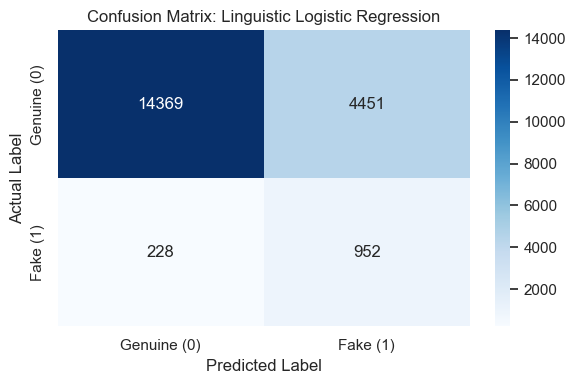

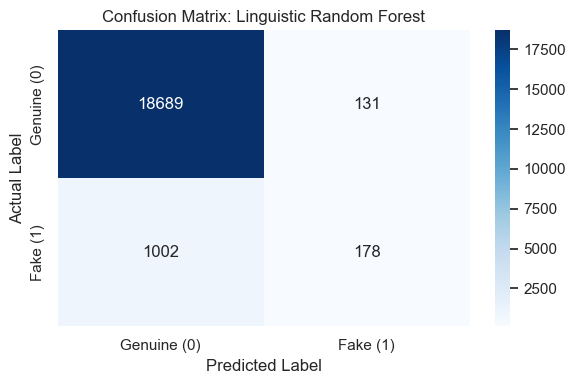

In [12]:
# Function to save confusion matrix figure
def save_confusion_matrix(y_true, y_pred, title, filename):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Genuine (0)", "Fake (1)"],
        yticklabels=["Genuine (0)", "Fake (1)"]
    )
    plt.title(title)
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.savefig(filename, dpi=300)
    plt.show()

save_confusion_matrix(
    y_test,
    y_pred_lr,
    "Confusion Matrix: Linguistic Logistic Regression",
    "outputs/confusion_matrix_linguistic_logistic.png"
)

save_confusion_matrix(
    y_test,
    y_pred_rf,
    "Confusion Matrix: Linguistic Random Forest",
    "outputs/confusion_matrix_linguistic_random_forest.png"
)


## 11. Feature Importance: Random Forest

The Random Forest model is used to inspect which linguistic features contribute most strongly to prediction. One hot encoded categorical features are expanded before extracting feature importance values.


<Figure size 1000x600 with 0 Axes>

<Axes: xlabel='importance', ylabel='feature'>

Text(0.5, 1.0, 'Top 15 Linguistic Feature Importances: Random Forest')

Text(0.5, 0, 'Importance')

Text(0, 0.5, 'Feature')

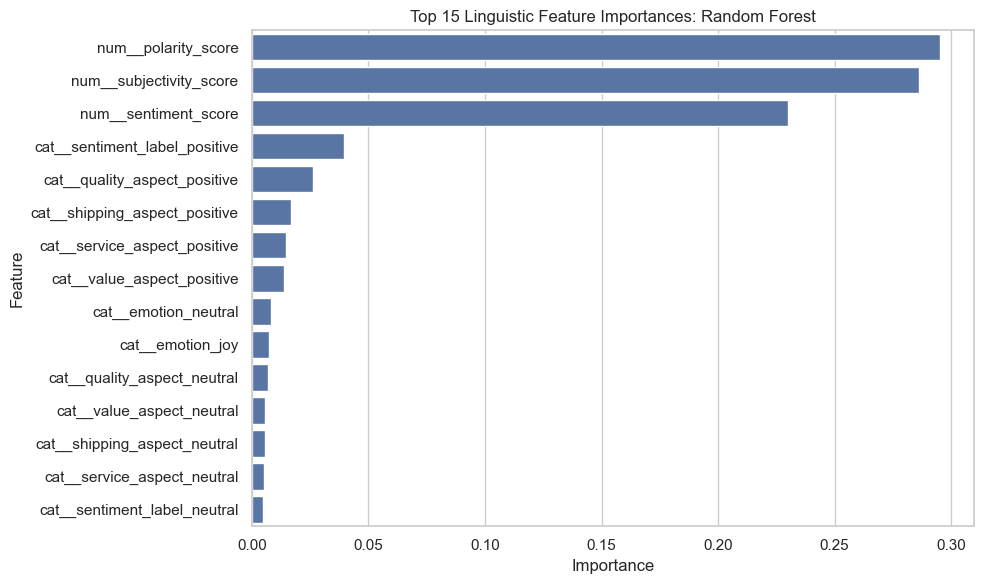

,feature,importance
2,num__polarity_score,0.295003
1,num__subjectivity_score,0.285972
0,num__sentiment_score,0.229813
6,cat__sentiment_label_positive,0.039440
9,cat__quality_aspect_positive,0.026285
12,cat__shipping_aspect_positive,0.016834
18,cat__service_aspect_positive,0.014554
15,cat__value_aspect_positive,0.013651
27,cat__emotion_neutral,0.008234
24,cat__emotion_joy,0.007290


In [13]:
# Extract feature names after preprocessing
try:
    fitted_preprocessor = rf_model.named_steps["preprocess"]
    feature_names = fitted_preprocessor.get_feature_names_out()
    importances = rf_model.named_steps["model"].feature_importances_

    feature_importance = pd.DataFrame({
        "feature": feature_names,
        "importance": importances
    }).sort_values("importance", ascending=False)

    feature_importance.to_csv("outputs/feature_importance_linguistic_random_forest.csv", index=False)

    top_n = 15
    plt.figure(figsize=(10, 6))
    sns.barplot(
        data=feature_importance.head(top_n),
        x="importance",
        y="feature"
    )
    plt.title(f"Top {top_n} Linguistic Feature Importances: Random Forest")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.savefig("outputs/feature_importance_linguistic_random_forest.png", dpi=300)
    plt.show()

    display(feature_importance.head(20))
except Exception as e:
    print("Feature importance could not be extracted:", e)


## 12. Error Analysis

This step prepares a simple error analysis table by identifying false positives and false negatives from the Logistic Regression model. The same approach can be repeated for Random Forest if needed.


In [14]:
# Build error analysis table for Logistic Regression
error_df = X_test.copy()
error_df["actual"] = y_test.values
error_df["predicted_logistic"] = y_pred_lr

false_positives = error_df[(error_df["actual"] == 0) & (error_df["predicted_logistic"] == 1)]
false_negatives = error_df[(error_df["actual"] == 1) & (error_df["predicted_logistic"] == 0)]

print("Logistic Regression false positives:", false_positives.shape[0])
print("Logistic Regression false negatives:", false_negatives.shape[0])

false_positives.head()


Logistic Regression false positives: 4451
Logistic Regression false negatives: 228


,sentiment_score,subjectivity_score,polarity_score,sentiment_label,quality_aspect,shipping_aspect,value_aspect,service_aspect,emotion,is_sarcastic,actual,predicted_logistic
8097,1.00,0.413,0.751,positive,positive,positive,positive,positive,joy,0,0,1
3073,1.00,0.908,0.864,positive,positive,positive,positive,positive,joy,0,0,1
66818,0.93,0.678,0.887,positive,positive,positive,positive,neutral,joy,0,0,1
26515,1.00,0.620,0.843,positive,positive,positive,positive,positive,delight,0,0,1
94355,1.00,0.600,0.813,positive,positive,positive,neutral,neutral,delight,0,0,1


In [15]:
false_negatives.head()


,sentiment_score,subjectivity_score,polarity_score,sentiment_label,quality_aspect,shipping_aspect,value_aspect,service_aspect,emotion,is_sarcastic,actual,predicted_logistic
5685,0.394,0.772,0.299,positive,positive,positive,neutral,neutral,neutral,0,1,0
78760,-1.000,0.700,-0.742,negative,negative,negative,negative,negative,anger,0,1,0
10759,0.491,0.511,0.573,positive,positive,positive,neutral,neutral,satisfaction,0,1,0
37456,-0.797,0.784,-1.000,negative,negative,neutral,negative,neutral,frustration,0,1,0
23299,1.000,0.418,0.718,positive,positive,neutral,positive,neutral,joy,0,1,0


In [16]:
# Save sample error cases for later report discussion
false_positives.head(20).to_csv("outputs/logistic_false_positives_sample.csv", index=False)
false_negatives.head(20).to_csv("outputs/logistic_false_negatives_sample.csv", index=False)

print("Error analysis samples saved.")


Error analysis samples saved.


## 13. Linguistic Model Summary

This phase builds fake review detection models using NLP derived linguistic features rather than raw review text. The selected features include sentiment score, polarity score, subjectivity score, aspect level sentiment, emotion, and sarcasm indicators.

Two models were trained: Logistic Regression and Random Forest. Both models used the same 80/20 stratified train/test split with `random_state=42` to ensure fair comparison with the baseline model.

The outputs include:

- `outputs/metrics.csv`
- `outputs/confusion_matrix_linguistic_logistic.png`
- `outputs/confusion_matrix_linguistic_random_forest.png`
- `outputs/feature_importance_linguistic_random_forest.png`

These results will be used later for comparison with the baseline model and the hybrid model.


In [17]:
# Final output check
print("Generated output files:")
for root, dirs, files in os.walk("outputs"):
    for file in files:
        print(os.path.join(root, file))


Generated output files:
outputs\confusion_matrix_linguistic_logistic.png
outputs\confusion_matrix_linguistic_random_forest.png
outputs\feature_importance_linguistic_random_forest.csv
outputs\feature_importance_linguistic_random_forest.png
outputs\logistic_false_negatives_sample.csv
outputs\logistic_false_positives_sample.csv
outputs\metrics.csv
